# Прогноз почасового спроса на велосипеды

## Описание

BikeSouth развивает городской велопрокат на юге России и хочет улучшить прогноз почасового спроса на аренду велосипедов. Раньше использовалась линейная регрессия, но она не учитывает нелинейные погодные эффекты: одна и та же температура при солнце и после дождя даёт разный спрос. Из-за этого система логистики то не успевает подвезти велосипеды к станциям, то они простаивают.

## Цель

Построить модель прогноза почасового спроса на аренду велосипедов по погодным и календарным признакам, которая превосходит по качеству действующую линейную регрессию.

## Задачи

1. Оценить качество текущей baseline-модели на train и test.
2. Провести исследовательский анализ данных, найти признаки с сильной связью с целевой переменной.
3. Подготовить данные и обучить базовые версии kNN и дерева решений.
4. Подобрать гиперпараметры обеих моделей через Optuna с единой схемой кросс-валидации.
5. Сравнить модели по RMSE, R² и MAE, выбрать лучшую и проверить её на тестовой выборке.
6. Оценить важность признаков и сформулировать рекомендации для BikeSouth.

## Данные

Два датасета с почасовыми данными об аренде и погоде: обучающая выборка `ds_s14_train_data.csv` и тестовая `ds_s14_test_data.csv`, которая используется только для финальной оценки. Признаки: температура, влажность, скорость ветра, видимость, точка росы, солнечная радиация, осадки, снегопад, сезон, праздничный день, рабочее состояние станций и время суток. Целевая переменная Rented Bike Count: число арендованных велосипедов за час.

## Подготовка данных

In [1]:
import joblib
import matplotlib.pyplot as plt
import optuna
import pandas as pd
import phik  # нужен для train.phik_matrix
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

In [2]:
DATA_DIR = 'datasets'
RANDOM_STATE = 333
N_FOLDS = 5

cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
train = pd.read_csv(f'{DATA_DIR}/ds_s14_train_data.csv')
test = pd.read_csv(f'{DATA_DIR}/ds_s14_test_data.csv')

train.shape, test.shape

((7008, 16), (1752, 16))

Названия столбцов приводятся к snake_case: на таких именах обучен baseline.

In [4]:
def columns_convertator(df):
    df = df.copy()
    df.columns = (df.columns
        .str.lower()
        .str.replace(r'[^a-z0-9_ ]', '', regex=True)
        .str.replace(' ', '_'))
    return df


train = columns_convertator(train)
test = columns_convertator(test)
TARGET = 'rented_bike_count'

assert (train.columns == test.columns).all()
train.columns

Index(['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
       'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm',
       'snowfall_cm', 'seasons', 'holiday', 'functioning_day',
       'time_period_evening', 'time_period_late_evening',
       'time_period_morning', 'time_period_night', 'rented_bike_count'],
      dtype='object')

In [5]:
X_train = train.drop(columns=TARGET)
X_test = test.drop(columns=TARGET)
y_train = train[TARGET]
y_test = test[TARGET]

## Baseline

Готовый пайплайн линейной регрессии, переданный компанией.

In [6]:
baseline = joblib.load('baseline_linear_regression_pipeline.joblib')
baseline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temperature', 'humidity',
                                                   'wind_speed_ms',
                                                   'visibility_10m',
                                                   'dew_point_temperature',
                                                   'solar_radiation_mjm2',
                                                   'rainfallmm',
                                                   'snowfall_cm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['seasons', 'holiday',
                                                   'functioning_day']),
                                                 ('time', 'passthrough',
                                                  ['time_period_evening',
                                                   'time_period_late_evening',
                                                   'time_period_morning',
                                                   'time_period_night'])])),
                ('model', LinearRegression())])

In [7]:
def scores(model, X, y):
    y_pred = model.predict(X)
    return {
        'RMSE': root_mean_squared_error(y, y_pred),
        'R2': r2_score(y, y_pred),
        'MAE': mean_absolute_error(y, y_pred),
    }


baseline_scores = pd.DataFrame({
    'train': scores(baseline, X_train, y_train),
    'test': scores(baseline, X_test, y_test),
})

baseline_scores

,train,test
RMSE,412.499623,411.454458
R2,0.592596,0.586293
MAE,309.152519,312.531298


Метрики на train и test близки, переобучения нет. R² около 0.59 говорит о том, что линейная модель плохо описывает нелинейные связи в данных. Эти значения служат опорой для сравнения новых моделей.

## Исследовательский анализ данных

In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float64
 1   humidity                  6758 non-null   float64
 2   wind_speed_ms             6798 non-null   float64
 3   visibility_10m            6749 non-null   float64
 4   dew_point_temperature     7008 non-null   float64
 5   solar_radiation_mjm2      6798 non-null   float64
 6   rainfallmm                6746 non-null   float64
 7   snowfall_cm               6745 non-null   float64
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   object 
 10  functioning_day           7008 non-null   object 
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_per

In [9]:
train.isna().sum()

temperature                   0
humidity                    250
wind_speed_ms               210
visibility_10m              259
dew_point_temperature         0
solar_radiation_mjm2        210
rainfallmm                  262
snowfall_cm                 263
seasons                       0
holiday                       0
functioning_day               0
time_period_evening           0
time_period_late_evening      0
time_period_morning           0
time_period_night             0
rented_bike_count             0
dtype: int64

In [10]:
train.nunique()

temperature                  541
humidity                      87
wind_speed_ms                 64
visibility_10m              1697
dew_point_temperature        547
solar_radiation_mjm2         344
rainfallmm                    53
snowfall_cm                   47
seasons                        4
holiday                        2
functioning_day                2
time_period_evening            2
time_period_late_evening       2
time_period_morning            2
time_period_night              2
rented_bike_count           2024
dtype: int64

Пропуски есть только в числовых погодных признаках, их нужно обработать. Категориальные и бинарные признаки нужно закодировать.

### Целевая переменная

In [11]:
y_train.describe()

count    7008.000000
mean      705.606022
std       646.311790
min         0.000000
25%       190.750000
50%       504.500000
75%      1070.000000
max      3556.000000
Name: rented_bike_count, dtype: float64

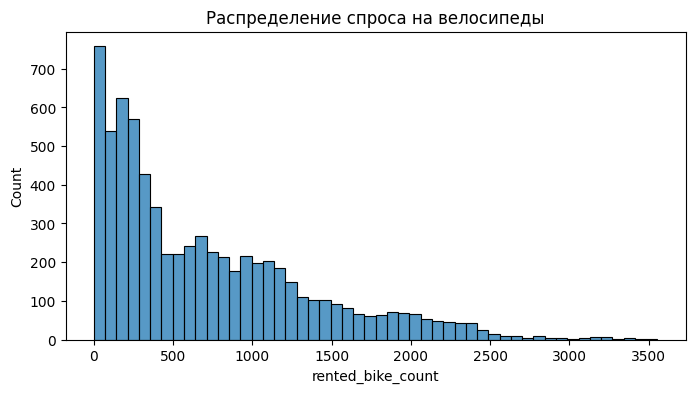

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(y_train, bins=50, ax=ax)
ax.set_title('Распределение спроса на велосипеды')
plt.show()

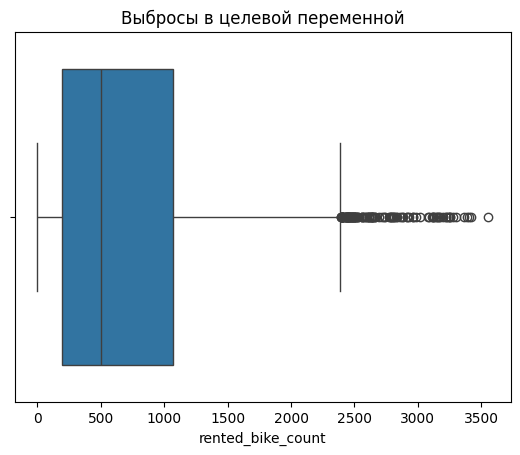

In [13]:
sns.boxplot(x=y_train)
plt.title('Выбросы в целевой переменной')
plt.show()

Пропусков в целевой переменной нет. Распределение с длинным правым хвостом: медиана заметно ниже среднего.

### Зависимость спроса от погоды

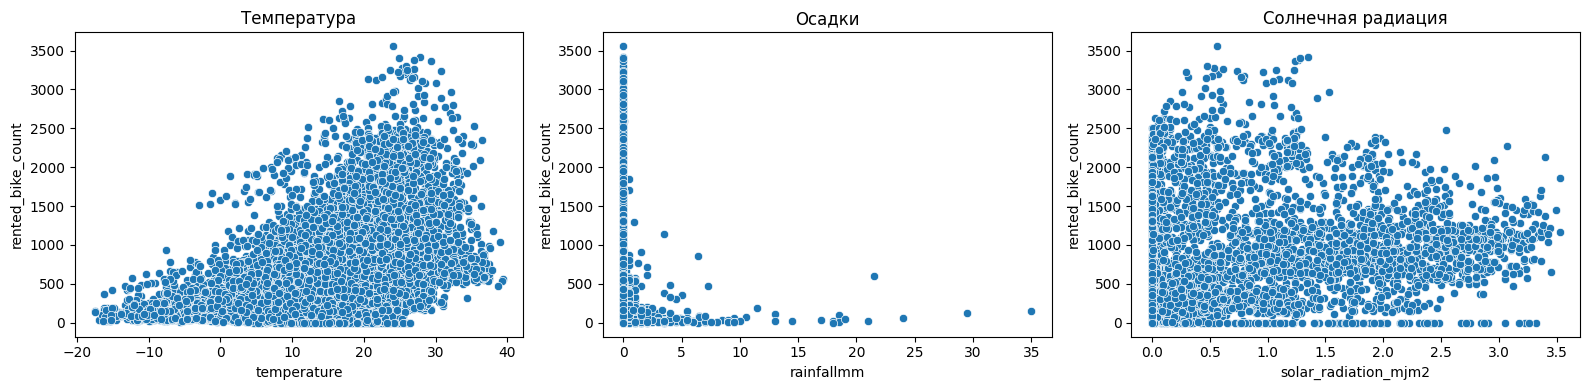

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cols = ['temperature', 'rainfallmm', 'solar_radiation_mjm2']
titles = ['Температура', 'Осадки', 'Солнечная радиация']

for ax, col, title in zip(axes, cols, titles):
    sns.scatterplot(data=train, x=col, y=TARGET, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

Зависимость от температуры нелинейная, с пиком около 25-30 °C. От осадков зависимость пороговая: при дожде спрос резко падает. Для солнечной радиации выраженной связи на графике не видно.

### Сезоны и праздники

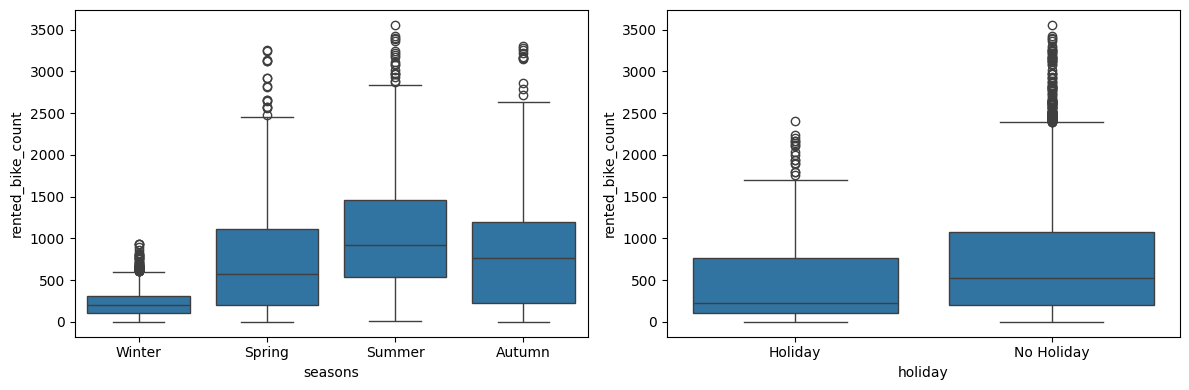

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train, x='seasons', y=TARGET,
            order=['Winter', 'Spring', 'Summer', 'Autumn'], ax=axes[0])
sns.boxplot(data=train, x='holiday', y=TARGET, ax=axes[1])
plt.tight_layout()
plt.show()

Спрос растёт от зимы к лету и снова падает к осени. Зимой он заметно ниже всех остальных сезонов, летом медиана самая высокая, а разброс шире. В обычные дни медиана и разброс спроса выше, чем в праздничные.

### Корреляции

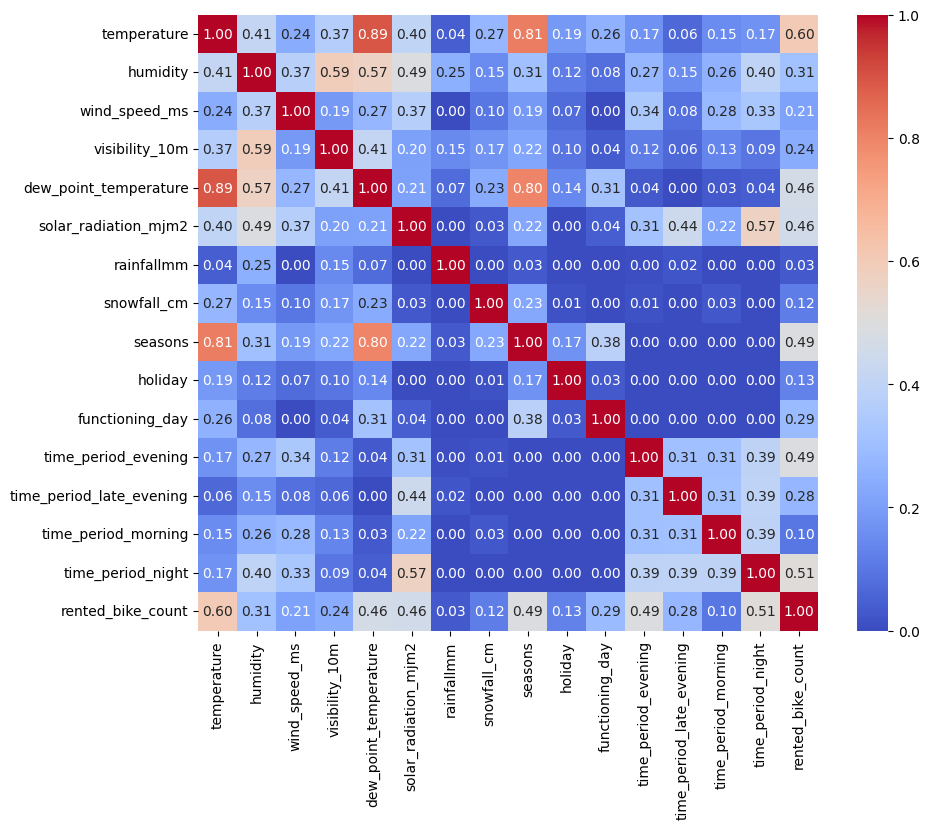

In [16]:
# phik корректно работает с категориальными признаками
num_cols = ['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
            'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm']

phik_matrix = train.phik_matrix(interval_cols=num_cols + [TARGET])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
plt.show()

Сильнее всего с целевой переменной связана температура, следом идут время суток и сезон, чуть слабее точка росы и солнечная радиация. Осадки показывают связь заметно слабее остальных, хотя на графиках дождь выглядит выраженным фактором. Расхождение объясняется биннингом в phik: подавляющая часть значений осадков равна нулю, и метод не улавливает разницу. Значимость проверяется критерием Манна-Уитни с порогом 0.05.

In [17]:
# осадки сводятся к двум группам: с дождём и без
rain = train.loc[train['rainfallmm'] > 0, TARGET]
no_rain = train.loc[train['rainfallmm'] == 0, TARGET]

stat, p = mannwhitneyu(rain, no_rain)
print(f'p-value: {p:.4g}')

p-value: 8.155e-111


p-value на много порядков ниже порога: спрос в часы с дождём и без него различается статистически значимо.

### Итоги EDA

Целевая переменная скошена вправо, выбросы есть только сверху: снизу их быть не может из-за нулевого минимума спроса. Сезонные колебания выражены сильно, зимой спрос заметно ниже, чем летом. Зависимость от температуры нелинейная: спрос растёт до середины диапазона и падает в жару. От осадков спрос зависит пороговым образом: любой дождь резко снижает его независимо от количества. От солнечной радиации выраженной зависимости не видно. В обычные дни спрос выше, чем в праздничные. По корреляциям сильнее всего с целевой переменной связаны температура, время суток и сезон. Критерий Манна-Уитни подтвердил значимость влияния осадков.

## Обучение моделей

### Предобработка

Числовые признаки: пропуски заполняются медианой, для kNN добавляется масштабирование. Категориальные: пропуски заполняются модой, затем one-hot кодирование. Бинарные признаки времени суток передаются без изменений. Лишний столбец после one-hot (дамми-ловушка) не мешает ни kNN, ни дереву, поэтому первая категория не удаляется.

In [18]:
num_cols = ['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m',
            'dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm']
cat_cols = ['seasons', 'holiday', 'functioning_day']
time_cols = ['time_period_evening', 'time_period_late_evening',
             'time_period_morning', 'time_period_night']

num_pipeline_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

num_pipeline_dectree = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor_knn = ColumnTransformer([
    ('num', num_pipeline_knn, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('time', 'passthrough', time_cols),
])

preprocessor_dectree = ColumnTransformer([
    ('num', num_pipeline_dectree, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('time', 'passthrough', time_cols),
])

### Базовые параметры

Пайплайны с параметрами по умолчанию обучаются на всём train. Это проверка работоспособности, а не честная валидация.

In [19]:
full_knn_pipeline = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', KNeighborsRegressor(n_neighbors=5)),
])

full_dectree_pipeline = Pipeline([
    ('preprocessor', preprocessor_dectree),
    ('model', DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)),
])

full_knn_pipeline.fit(X_train, y_train)
full_dectree_pipeline.fit(X_train, y_train)

pd.DataFrame({
    'baseline': baseline_scores['train'],
    'KNN': scores(full_knn_pipeline, X_train, y_train),
    'DecisionTree': scores(full_dectree_pipeline, X_train, y_train),
})

,baseline,KNN,DecisionTree
RMSE,412.499623,261.392240,267.236030
R2,0.592596,0.836408,0.829011
MAE,309.152519,170.332991,169.937739


С параметрами по умолчанию обе модели заметно лучше baseline: RMSE около 260 против 412, R² около 0.83 против 0.59. kNN немного впереди дерева по RMSE и R², по MAE модели практически равны. Дальше модели сравниваются по кросс-валидации.

## Подбор гиперпараметров

Подбор через Optuna: по 50 попыток для каждой модели, целевая метрика RMSE по 5-фолдовой кросс-валидации. Схема кросс-валидации одна для обеих моделей.

In [20]:
def objective_dectree(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 3, 100),
        'criterion': trial.suggest_categorical('criterion', ['squared_error', 'absolute_error', 'poisson']),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 15),
    }

    pipeline = Pipeline([
        ('preprocessor', preprocessor_dectree),
        ('model', DecisionTreeRegressor(random_state=RANDOM_STATE, **params)),
    ])

    rmse = cross_val_score(pipeline, X_train, y_train, cv=cv,
                           scoring='neg_root_mean_squared_error')
    return -rmse.mean()


study_dectree = optuna.create_study(
    direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_dectree.optimize(objective_dectree, n_trials=50)

print(study_dectree.best_params)
print(study_dectree.best_value)

{'max_depth': 12, 'min_samples_split': 100, 'criterion': 'squared_error', 'min_samples_leaf': 5}
318.1322926582473


In [21]:
def objective_knn(trial):
    params = {
        'n_neighbors': trial.suggest_int('n_neighbors', 3, 20),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'p': trial.suggest_int('p', 1, 3),
    }

    pipeline = Pipeline([
        ('preprocessor', preprocessor_knn),
        ('model', KNeighborsRegressor(**params)),
    ])

    rmse = cross_val_score(pipeline, X_train, y_train, cv=cv,
                           scoring='neg_root_mean_squared_error')
    return -rmse.mean()


study_knn = optuna.create_study(
    direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_knn.optimize(objective_knn, n_trials=50)

print(study_knn.best_params)
print(study_knn.best_value)

{'n_neighbors': 9, 'weights': 'distance', 'p': 1}
305.7415770851816


Лучшие параметры kNN: 9 соседей, взвешивание по расстоянию, манхэттенская метрика. Лучшие параметры дерева: глубина 12, не менее 100 объектов для разбиения и 5 в листе, критерий squared_error. По RMSE на кросс-валидации kNN впереди дерева.

## Кросс-валидация

Модели с подобранными параметрами проверяются на тех же фолдах.

In [22]:
best_knn = KNeighborsRegressor(**study_knn.best_params)
best_dectree = DecisionTreeRegressor(**study_dectree.best_params, random_state=RANDOM_STATE)

final_knn_pipeline = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', best_knn),
])

final_dectree_pipeline = Pipeline([
    ('preprocessor', preprocessor_dectree),
    ('model', best_dectree),
])

scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
}


def cv_summary(res):
    return pd.Series({
        'RMSE': -res['test_RMSE'].mean(),
        'R2': res['test_R2'].mean(),
        'MAE': -res['test_MAE'].mean(),
    })


cv_knn = cross_validate(final_knn_pipeline, X_train, y_train, cv=cv, scoring=scoring)
cv_dectree = cross_validate(final_dectree_pipeline, X_train, y_train, cv=cv, scoring=scoring)

cv_results = pd.DataFrame({
    'KNN': cv_summary(cv_knn),
    'DecisionTree': cv_summary(cv_dectree),
})

cv_results

,KNN,DecisionTree
RMSE,305.741577,318.132293
R2,0.775448,0.756625
MAE,203.600992,214.580797


На кросс-валидации kNN немного лучше дерева по всем метрикам.

## Сравнение с baseline

Метрики baseline считаются на всём train, для kNN и дерева берутся средние по кросс-валидации.

In [23]:
comparison = pd.DataFrame({
    'baseline': baseline_scores['train'],
    'KNN': cv_results['KNN'],
    'DecisionTree': cv_results['DecisionTree'],
})

comparison

,baseline,KNN,DecisionTree
RMSE,412.499623,305.741577,318.132293
R2,0.592596,0.775448,0.756625
MAE,309.152519,203.600992,214.580797


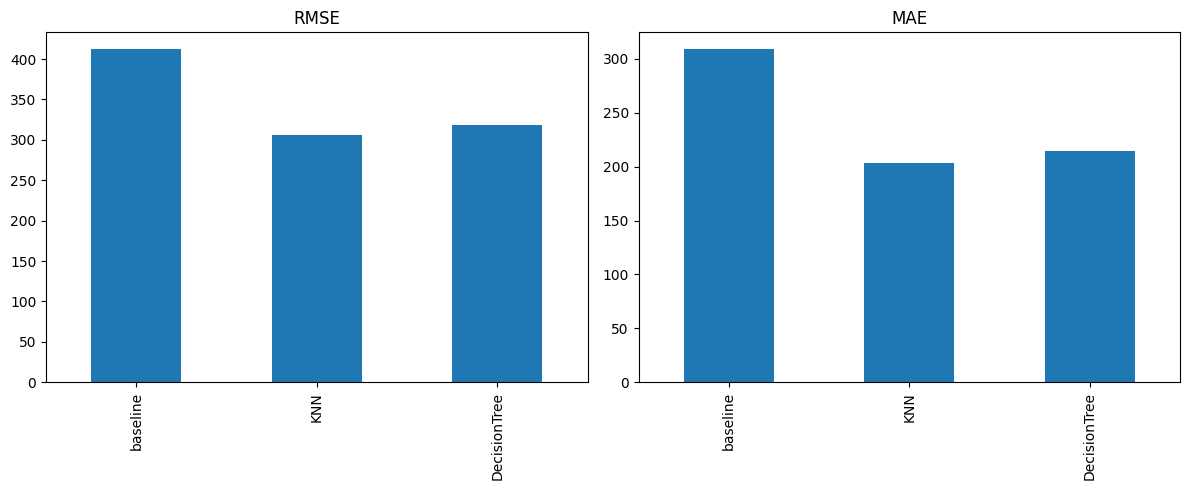

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
comparison.loc['RMSE'].plot(kind='bar', ax=axes[0], title='RMSE')
comparison.loc['MAE'].plot(kind='bar', ax=axes[1], title='MAE')
plt.tight_layout()
plt.show()

kNN точнее: там, где baseline в среднем промахивался почти на 310 велосипедов в час, kNN ошибается примерно на 200. По EDA основной обвал спроса происходит уже при минимальном дожде, а дальнейшее усиление осадков снижает спрос заметно слабее. Линейная модель с одним коэффициентом на весь диапазон осадков плохо описывает такую форму зависимости, а дерево и kNN улавливают подобные пороги. Это одна из причин прироста качества у обеих новых моделей.

## Финальная модель

По кросс-валидации лучшая модель kNN. Оценка на тестовой выборке:

In [25]:
final_knn_pipeline.fit(X_train, y_train)
final_scores = scores(final_knn_pipeline, X_test, y_test)

pd.DataFrame({
    'baseline': baseline_scores['test'],
    'KNN': final_scores,
    'KNN (CV)': cv_results['KNN'],
})

,baseline,KNN,KNN (CV)
RMSE,411.454458,310.510442,305.741577
R2,0.586293,0.764385,0.775448
MAE,312.531298,206.324828,203.600992


На тесте kNN заметно превосходит baseline по всем трём метрикам. Результат на тесте близок к оценке по кросс-валидации, модель обобщается стабильно.

In [26]:
joblib.dump(final_knn_pipeline, 'model_for_export.joblib')

model_for_export = joblib.load('model_for_export.joblib')
assert (model_for_export.predict(X_test) == final_knn_pipeline.predict(X_test)).all()

## Важность признаков

У kNN нет встроенной оценки важности признаков, поэтому она считается по дереву решений как второй по качеству модели.

In [27]:
final_dectree_pipeline.fit(X_train, y_train)

preprocessor = final_dectree_pipeline.named_steps['preprocessor']
model = final_dectree_pipeline.named_steps['model']

feature_importance = pd.DataFrame({
    'feature': preprocessor.get_feature_names_out(),
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

feature_importance

,feature,importance
0,num__temperature,0.353623
19,time__time_period_night,0.176239
1,num__humidity,0.119217
16,time__time_period_evening,0.090664
15,cat__functioning_day_Yes,0.087991
17,time__time_period_late_evening,0.047172
11,cat__seasons_Winter,0.035486
5,num__solar_radiation_mjm2,0.026863
4,num__dew_point_temperature,0.014772
6,num__rainfallmm,0.014524


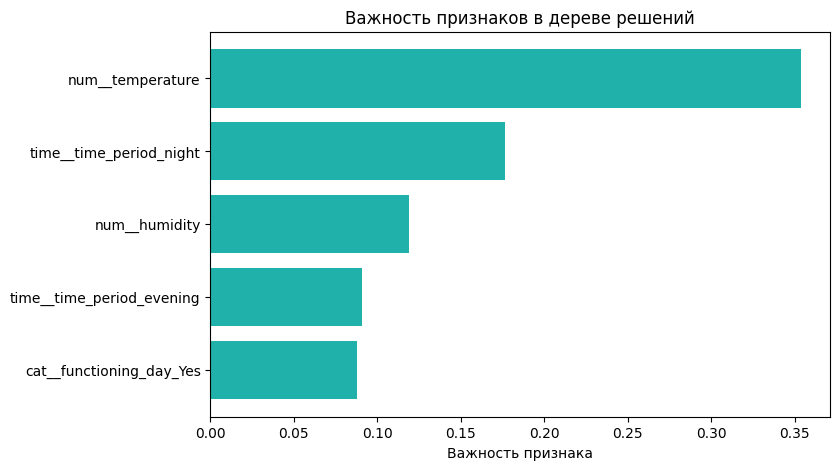

In [28]:
top_5 = feature_importance.head(5)

plt.figure(figsize=(8, 5))
plt.barh(top_5['feature'], top_5['importance'], color='lightseagreen')
plt.xlabel('Важность признака')
plt.title('Важность признаков в дереве решений')
plt.gca().invert_yaxis()
plt.show()

Сильнее всего на спрос влияет температура, за ней идут время суток (прежде всего ночные часы), влажность и то, работает ли станция. Сезон и осадки играют менее значимую, но не нулевую роль. Температура и время суток лидировали и в корреляционном анализе.

## Дополнительные признаки

Кастомный трансформер добавляет два признака: бинарный флаг дождя `is_rain` и произведение температуры на влажность `temp_humidity`. Он встраивается в пайплайн перед препроцессором.

In [29]:
class FeatureAdder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['is_rain'] = (X['rainfallmm'] > 0).astype(int)
        X['temp_humidity'] = X['temperature'] * X['humidity']
        return X


X_with_features = FeatureAdder().fit_transform(X_train)
X_with_features.head()

,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,seasons,holiday,functioning_day,time_period_evening,time_period_late_evening,time_period_morning,time_period_night,is_rain,temp_humidity
0,20.3,35.0,2.4,2000.0,4.3,0.46,0.0,0.0,Autumn,Holiday,Yes,True,False,False,False,0,710.5
1,25.4,55.0,3.2,2000.0,15.6,0.15,0.0,0.0,Autumn,No Holiday,Yes,True,False,False,False,0,1397.0
2,-6.9,39.0,1.6,2000.0,-18.5,0.00,0.0,0.0,Winter,No Holiday,Yes,False,True,False,False,0,-269.1
3,-5.2,37.0,2.2,2000.0,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,False,False,False,True,0,-192.4
4,23.4,34.0,2.1,2000.0,6.6,2.84,0.0,0.0,Autumn,No Holiday,Yes,False,False,False,False,0,795.6


In [30]:
preprocessor_knn_features = ColumnTransformer([
    ('num', num_pipeline_knn, num_cols + ['temp_humidity']),
    ('cat', cat_pipeline, cat_cols),
    ('time_bin', 'passthrough', time_cols + ['is_rain']),
])

preprocessor_dectree_features = ColumnTransformer([
    ('num', num_pipeline_dectree, num_cols + ['temp_humidity']),
    ('cat', cat_pipeline, cat_cols),
    ('time_bin', 'passthrough', time_cols + ['is_rain']),
])

knn_features_pipeline = Pipeline([
    ('feature_adder', FeatureAdder()),
    ('preprocessor', preprocessor_knn_features),
    ('model', best_knn),
])

dectree_features_pipeline = Pipeline([
    ('feature_adder', FeatureAdder()),
    ('preprocessor', preprocessor_dectree_features),
    ('model', best_dectree),
])

cv_knn_features = cross_validate(knn_features_pipeline, X_train, y_train, cv=cv, scoring=scoring)
cv_dectree_features = cross_validate(dectree_features_pipeline, X_train, y_train, cv=cv, scoring=scoring)

comparison_features = pd.DataFrame({
    'KNN': cv_results['KNN'],
    'KNN + признаки': cv_summary(cv_knn_features),
    'DecisionTree': cv_results['DecisionTree'],
    'DecisionTree + признаки': cv_summary(cv_dectree_features),
})

comparison_features

,KNN,KNN + признаки,DecisionTree,DecisionTree + признаки
RMSE,305.741577,303.955922,318.132293,319.188222
R2,0.775448,0.778045,0.756625,0.754992
MAE,203.600992,202.729778,214.580797,214.736329


Метрики kNN с новыми признаками на тестовой выборке:

In [31]:
knn_features_pipeline.fit(X_train, y_train)

pd.DataFrame({
    'KNN': final_scores,
    'KNN + признаки': scores(knn_features_pipeline, X_test, y_test),
})

,KNN,KNN + признаки
RMSE,310.510442,301.619305
R2,0.764385,0.777685
MAE,206.324828,200.456249


На kNN новые признаки дали небольшой, но стабильный прирост: ошибка снизилась и на кросс-валидации, и на тесте. На дереве эффект обратный: оно само находит порог по осадкам через разбиение, а kNN считает расстояния по сырым значениям и без явного признака такие пороги не улавливает. Польза от ручных признаков зависит от алгоритма.

## Выводы

Лучшей моделью оказался kNN. На тесте RMSE около 310 против 411 у baseline, R² 0.76 против 0.59, MAE около 206 против 313: ошибка по RMSE ниже на четверть, по MAE примерно на треть. Дерево решений показало близкий, но чуть более слабый результат. Линейная регрессия не справляется с нелинейностью и пороговыми эффектами, найденными на EDA: резким падением спроса при первом дожде и зависимостью от температуры с пиком в середине диапазона.

Новые признаки `is_rain` и `temp_humidity` дают kNN небольшое дополнительное улучшение: на тесте RMSE около 302, R² около 0.78.

Рекомендации для BikeSouth:

1. Использовать kNN вместо линейной регрессии для прогноза почасового спроса.
2. Добавить в данные почасовой прогноз осадков вместо агрегированных значений.
3. Добавить признаки выходных и будних дней в связке со временем суток.